# Exercício 4 — Outliers
**Dataset:** Diamonds (seaborn)

O desafio aqui é separar o que é **erro de registro** do que é **diamante raro de verdade**.

In [1]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', 30)

In [2]:
# CARREGAMENTO DOS DADOS
df = sns.load_dataset('diamonds')
print(df.shape)
df.head()

(53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


## Estatísticas descritivas e valores impossíveis

Antes de tudo, o significado das colunas (pela documentação do dataset):
- `carat`: peso em quilates (1 quilate = 0,2 g)
- `x`, `y`, `z`: **comprimento, largura e profundidade em milímetros**
- `depth`: profundidade total em %, calculada como `z / média(x, y) * 100`
- `table`: largura da "mesa" (a face de cima) em relação ao ponto mais largo, em %
- `price`: preço em dólares

In [3]:
# ESTATÍSTICAS DESCRITIVAS E VALORES IMPOSSÍVEIS
num_cols = df.select_dtypes(include='number').columns.tolist()
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
carat,53940.0,0.797940,0.474011,0.2,0.40,0.70,1.04,5.01
depth,53940.0,61.749405,1.432621,43.0,61.00,61.80,62.50,79.00
table,53940.0,57.457184,2.234491,43.0,56.00,57.00,59.00,95.00
price,53940.0,3932.799722,3989.439738,326.0,950.00,2401.00,5324.25,18823.00
x,53940.0,5.731157,1.121761,0.0,4.71,5.70,6.54,10.74
y,53940.0,5.734526,1.142135,0.0,4.72,5.71,6.54,58.90
z,53940.0,3.538734,0.705699,0.0,2.91,3.53,4.04,31.80


In [4]:
# dimensões zeradas: um diamante com 0 mm de largura não existe
print('Zeros em x, y, z:', (df[['x', 'y', 'z']] == 0).sum().to_dict())
print('Linhas com pelo menos uma dimensão zerada:', (df[['x', 'y', 'z']] == 0).any(axis=1).sum())
df[(df[['x', 'y', 'z']] == 0).any(axis=1)].head(8)

Zeros em x, y, z: {'x': 8, 'y': 7, 'z': 20}
Linhas com pelo menos uma dimensão zerada: 20


,carat,cut,color,clarity,depth,table,price,x,y,z
2207,1.00,Premium,G,SI2,59.1,59.0,3142,6.55,6.48,0.0
2314,1.01,Premium,H,I1,58.1,59.0,3167,6.66,6.60,0.0
4791,1.10,Premium,G,SI2,63.0,59.0,3696,6.50,6.47,0.0
5471,1.01,Premium,F,SI2,59.2,58.0,3837,6.50,6.47,0.0
10167,1.50,Good,G,I1,64.0,61.0,4731,7.15,7.04,0.0
11182,1.07,Ideal,F,SI2,61.6,56.0,4954,0.00,6.62,0.0
11963,1.00,Very Good,H,VS2,63.3,53.0,5139,0.00,0.00,0.0
13601,1.15,Ideal,G,VS2,59.2,56.0,5564,6.88,6.83,0.0


In [5]:
# dimensões gigantes: y = 58,9 mm é quase 6 cm. O maior diamante da base tem 5 quilates e ~10,7 mm.
df[(df['y'] > 20) | (df['z'] > 20)]

,carat,cut,color,clarity,depth,table,price,x,y,z
24067,2.00,Premium,H,SI2,58.9,57.0,12210,8.09,58.90,8.06
48410,0.51,Very Good,E,VS1,61.8,54.7,1970,5.12,5.15,31.80
49189,0.51,Ideal,E,VS1,61.8,55.0,2075,5.15,31.80,5.12


In [6]:
# conferência cruzada: depth deveria ser igual a z / média(x, y) * 100
com_dim = df[(df[['x', 'y', 'z']] > 0).all(axis=1)].copy()
com_dim['depth_calculado'] = com_dim['z'] / ((com_dim['x'] + com_dim['y']) / 2) * 100
com_dim['diferenca'] = (com_dim['depth_calculado'] - com_dim['depth']).abs()
inconsistentes = com_dim[com_dim['diferenca'] > 5]
print('Diamantes em que o depth informado não bate com x, y, z (diferença > 5 pontos):', len(inconsistentes))
inconsistentes[['carat', 'depth', 'depth_calculado', 'x', 'y', 'z', 'price']].round(2).sort_values('depth_calculado')

Diamantes em que o depth informado não bate com x, y, z (diferença > 5 pontos): 27


,carat,depth,depth_calculado,x,y,z,price
14635,1.07,60.6,16.10,6.62,6.67,1.07,5909
21654,1.41,60.7,19.41,7.31,7.22,1.41,9752
20694,1.53,61.9,20.50,7.43,7.50,1.53,8971
24067,2.00,58.9,24.06,8.09,58.90,8.06,12210
49189,0.51,61.8,27.71,5.15,31.80,5.12,2075
47138,0.55,61.0,42.25,5.31,5.34,2.25,1831
39246,0.38,60.9,43.88,4.71,4.68,2.06,1068
33102,0.34,57.0,46.89,6.65,4.61,2.64,816
2941,1.00,62.8,51.24,6.26,6.19,3.19,3293
38734,0.36,61.4,54.92,4.64,4.61,2.54,1043


**Valores fisicamente impossíveis que encontrei:**

1. **20 diamantes com alguma dimensão igual a 0** (`z = 0` em todos eles, alguns com `x` e `y` zerados também). Não existe objeto com 0 mm. Provavelmente "0" foi usado para "não medido".
2. **3 diamantes com dimensões gigantes**: `y = 58,9`, `y = 31,8` e `z = 31,8` mm. Um de 0,51 quilate com 31,8 mm seria do tamanho de uma moeda grande e pesaria muito mais. Os outros valores da mesma linha são normais (ex.: x = 5,12, y = 5,15), então parece erro de digitação (31,8 no lugar de 3,18).
3. **Inconsistência entre colunas**: em ~27 diamantes o `depth` informado não bate com o calculado a partir de x, y, z. Alguns casos são bem reveladores: tem diamante com `carat = 1,07` e `z = 1,07`, `carat = 1,53` e `z = 1,53`, ou seja, alguém copiou o peso na coluna de profundidade.

Nenhum desses é "diamante raro", são erros de registro.

## Detecção — Z-score

In [7]:
# DETECÇÃO — Z-SCORE (|z| > 3)
z = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std()
out_z = z.abs() > 3
print('Linhas com outlier em pelo menos uma coluna (Z-score):', out_z.any(axis=1).sum())
out_z.sum().rename('outliers_zscore')

Linhas com outlier em pelo menos uma coluna (Z-score): 2350


carat     439
depth     685
table     336
price    1206
x          43
y          34
z          55
Name: outliers_zscore, dtype: int64

## Detecção — IQR

In [8]:
# DETECÇÃO — IQR (abaixo de Q1 - 1,5*IQR ou acima de Q3 + 1,5*IQR)
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out_iqr = (df[num_cols] < lim_inf) | (df[num_cols] > lim_sup)
print('Linhas com outlier em pelo menos uma coluna (IQR):', out_iqr.any(axis=1).sum())

comparacao = pd.DataFrame({'Z-score': out_z.sum(), 'IQR': out_iqr.sum(),
                           'limite inferior IQR': lim_inf, 'limite superior IQR': lim_sup,
                           'limite superior Z (média+3dp)': df[num_cols].mean() + 3 * df[num_cols].std()})
comparacao.round(2)

Linhas com outlier em pelo menos uma coluna (IQR): 6416


,Z-score,IQR,limite inferior IQR,limite superior IQR,limite superior Z (média+3dp)
carat,439,1889,-0.56,2.00,2.22
depth,685,2545,58.75,64.75,66.05
table,336,605,51.50,63.50,64.16
price,1206,3540,-5611.38,11885.62,15901.12
x,43,32,1.96,9.28,9.10
y,34,29,1.99,9.27,9.16
z,55,49,1.22,5.74,5.66


In [9]:
# os dois métodos pegam os erros que encontrei acima?
erros_dim = (df[['x', 'y', 'z']] == 0).any(axis=1) | (df['y'] > 20) | (df['z'] > 20)
print('Erros de dimensão (zero ou gigante):', erros_dim.sum())
print('   ... marcados pelo Z-score:', (erros_dim & out_z[['x', 'y', 'z']].any(axis=1)).sum())
print('   ... marcados pelo IQR    :', (erros_dim & out_iqr[['x', 'y', 'z']].any(axis=1)).sum())

Erros de dimensão (zero ou gigante): 23
   ... marcados pelo Z-score: 23
   ... marcados pelo IQR    : 23


O IQR aponta quase **3 vezes mais** linhas que o Z-score (6.416 contra 2.350). A diferença é maior justamente em `price` (3.540 contra 1.206) e `carat`. Isso acontece porque essas colunas são assimétricas: a cauda da direita é longa, e o IQR, que olha só o "miolo" dos dados, considera boa parte dessa cauda como outlier. O Z-score, por outro lado, é "inflado" pelos próprios valores altos (média e desvio aumentam), então o limite dele fica mais longe.

Os dois métodos pegam os erros grosseiros de dimensão (zeros e 58,9 mm). Mas nenhum dos dois detectaria os casos em que `z = carat`, porque esses valores, isoladamente, são plausíveis. Esses só aparecem cruzando colunas.

## Visualizações

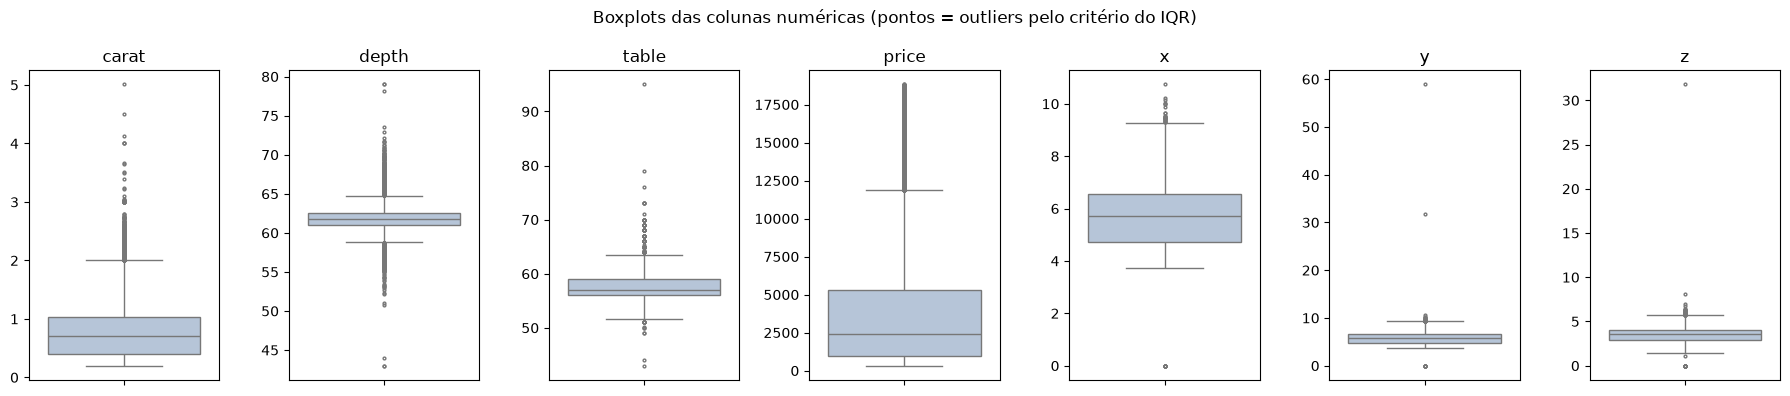

In [10]:
# VISUALIZAÇÕES — boxplots
fig, axes = plt.subplots(1, len(num_cols), figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color='lightsteelblue', flierprops={'markersize': 2})
    ax.set_title(col)
    ax.set_ylabel('')
plt.suptitle('Boxplots das colunas numéricas (pontos = outliers pelo critério do IQR)')
plt.tight_layout()
plt.show()

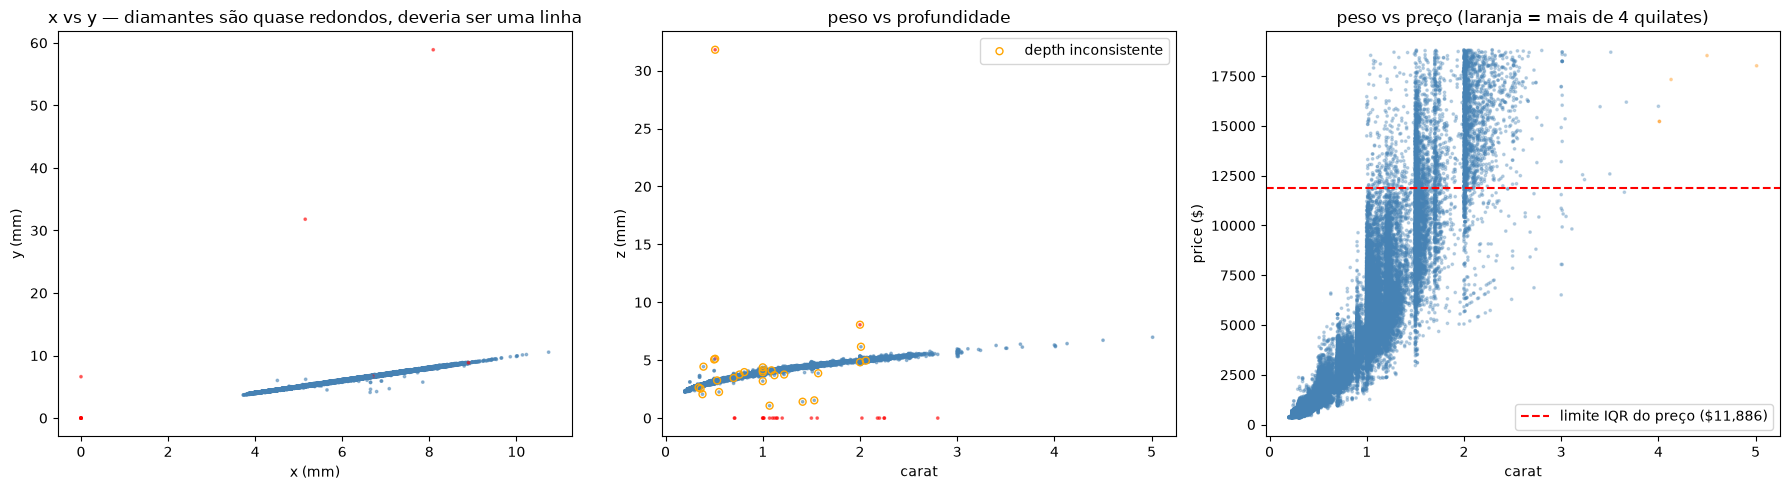

In [11]:
# dispersão: pares que fazem sentido físico
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cor = np.where(erros_dim, 'red', 'steelblue')
axes[0].scatter(df['x'], df['y'], s=3, c=cor, alpha=0.5)
axes[0].set_xlabel('x (mm)'); axes[0].set_ylabel('y (mm)')
axes[0].set_title('x vs y — diamantes são quase redondos, deveria ser uma linha')

axes[1].scatter(df['carat'], df['z'], s=3, c=cor, alpha=0.5)
axes[1].scatter(inconsistentes['carat'], inconsistentes['z'], s=25, facecolors='none', edgecolors='orange', label='depth inconsistente')
axes[1].set_xlabel('carat'); axes[1].set_ylabel('z (mm)')
axes[1].set_title('peso vs profundidade')
axes[1].legend()

axes[2].scatter(df['carat'], df['price'], s=3, alpha=0.3, c=np.where(df['carat'] > 4, 'darkorange', 'steelblue'))
axes[2].axhline(lim_sup['price'], color='red', linestyle='--', label=f"limite IQR do preço (${lim_sup['price']:,.0f})")
axes[2].set_xlabel('carat'); axes[2].set_ylabel('price ($)')
axes[2].set_title('peso vs preço (laranja = mais de 4 quilates)')
axes[2].legend()
plt.tight_layout()
plt.show()

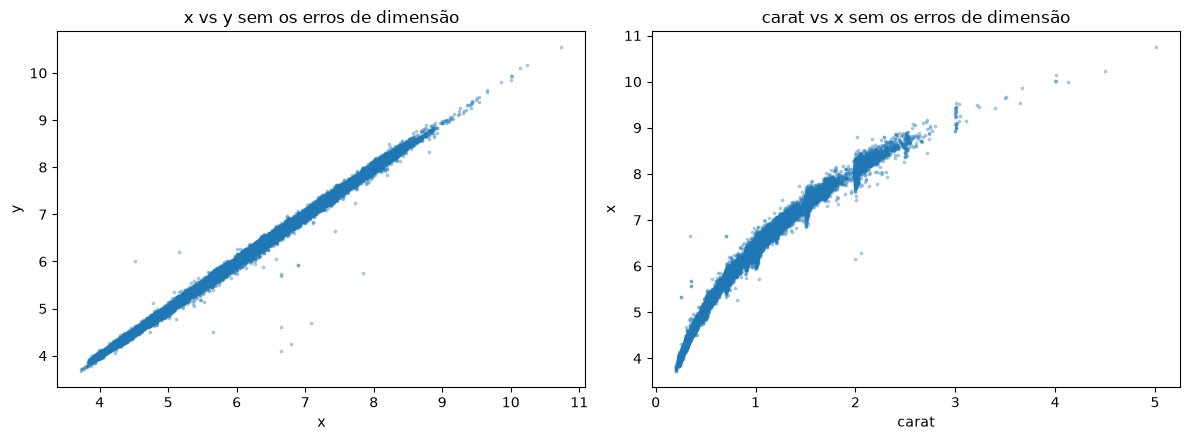

In [12]:
# o mesmo gráfico x vs y, mas sem os erros, para ver o padrão de verdade
ok = ~erros_dim
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(df.loc[ok, 'x'], df.loc[ok, 'y'], s=3, alpha=0.3)
axes[0].set_title('x vs y sem os erros de dimensão'); axes[0].set_xlabel('x'); axes[0].set_ylabel('y')
axes[1].scatter(df.loc[ok, 'carat'], df.loc[ok, 'x'], s=3, alpha=0.3)
axes[1].set_title('carat vs x sem os erros de dimensão'); axes[1].set_xlabel('carat'); axes[1].set_ylabel('x')
plt.tight_layout()
plt.show()

Os gráficos deixam a diferença bem clara:
- No `x` vs `y`, os diamantes formam uma linha quase perfeita (eles são praticamente redondos). Os pontos vermelhos, os erros, ficam totalmente fora: no zero ou lá em cima com 58,9 mm.
- No `carat` vs `price`, os diamantes acima do limite do IQR (linha tracejada) **seguem a tendência** dos outros: são mais pesados e, por isso, mais caros. Eles estão "longe" da maioria, mas estão onde a física e o mercado dizem que deveriam estar.
- Uma coisa curiosa que não tem a ver com outlier: aparecem "faixas verticais" em 1, 1,5 e 2 quilates. Tem muito mais diamante com exatamente esses pesos do que com 0,99 ou 1,95. Faz sentido, o mercado lapida para chegar em números redondos porque eles vendem melhor.
- Outra: no histograma de preço tem um "buraco" perto de $1.500 (nenhum diamante entre $1.454 e $1.546). Parece um defeito na coleta dos dados, não uma característica do mercado. Ele aparece também como uma falha no histograma do log mais abaixo.

## Erro x valor extremo legítimo

In [13]:
# ERRO x VALOR EXTREMO LEGÍTIMO
regra_zero = (df[['x', 'y', 'z']] == 0).any(axis=1)
regra_gigante = (df[['x', 'y', 'z']] > 20).any(axis=1)
depth_calc = df['z'] / ((df['x'] + df['y']) / 2) * 100
regra_depth = (df[['x', 'y', 'z']] > 0).all(axis=1) & ((depth_calc - df['depth']).abs() > 5)

df['classificacao'] = 'normal'
df.loc[out_iqr.any(axis=1), 'classificacao'] = 'extremo legítimo'
df.loc[regra_zero | regra_gigante | regra_depth, 'classificacao'] = 'erro de registro'

print(df['classificacao'].value_counts())
print()
print('Motivo dos erros:')
print(f'  dimensão zerada       : {regra_zero.sum()}')
print(f'  dimensão > 20 mm      : {regra_gigante.sum()}')
print(f'  depth não bate com xyz: {regra_depth.sum()}')

classificacao
normal              47510
extremo legítimo     6383
erro de registro       47
Name: count, dtype: int64

Motivo dos erros:
  dimensão zerada       : 20
  dimensão > 20 mm      : 3
  depth não bate com xyz: 27


In [14]:
# os extremos legítimos: quem são?
extremos = df[df['classificacao'] == 'extremo legítimo']
print('Diamantes com mais de 4 quilates:')
print(df[df['carat'] > 4][['carat', 'cut', 'color', 'clarity', 'depth', 'price', 'x', 'y', 'z', 'classificacao']])
print()
print('Preço por quilate (normal x extremo legítimo):')
print(df[df['classificacao'] != 'erro de registro'].assign(preco_por_quilate=lambda t: t['price'] / t['carat'])
      .groupby('classificacao')['preco_por_quilate'].describe().round(0))

Diamantes com mais de 4 quilates:
       carat      cut color clarity  depth  price      x      y     z  \
25998   4.01  Premium     I      I1   61.0  15223  10.14  10.10  6.17   
25999   4.01  Premium     J      I1   62.5  15223  10.02   9.94  6.24   
27130   4.13     Fair     H      I1   64.8  17329  10.00   9.85  6.43   
27415   5.01     Fair     J      I1   65.5  18018  10.74  10.54  6.98   
27630   4.50     Fair     J      I1   65.8  18531  10.23  10.16  6.72   

          classificacao  
25998  extremo legítimo  
25999  extremo legítimo  
27130  extremo legítimo  
27415  extremo legítimo  
27630  extremo legítimo  

Preço por quilate (normal x extremo legítimo):
                    count    mean     std     min     25%     50%     75%  \
classificacao                                                               
extremo legítimo   6383.0  6257.0  2739.0  1139.0  3755.0  6494.0  8312.0   
normal            47510.0  3705.0  1678.0  1051.0  2369.0  3342.0  4616.0   

              

**Critério que usei:**

Considero **erro de registro** quando o valor é fisicamente impossível ou contradiz outra coluna da mesma linha:
- dimensão igual a zero;
- dimensão maior que 20 mm (o diamante mais pesado da base, com 5 quilates, tem ~10,7 mm; 20 mm já é quase o dobro);
- `depth` informado diferente do `depth` calculado por x, y, z em mais de 5 pontos percentuais.

Considero **extremo legítimo** quando o valor é estatisticamente raro (fora do IQR), mas é coerente com o resto da linha. Os diamantes de 4 a 5 quilates, por exemplo, têm todas as dimensões proporcionais, são de clareza `I1` (a pior) e cor `I`/`J`, e custam entre $15 e $18,5 mil. É exatamente o que se espera de pedras grandes e de qualidade mais baixa. O preço por quilate dos "extremos" também está numa faixa plausível.

No total são **47 erros** contra **6.383 extremos legítimos**. Ou seja: a grande maioria do que os métodos estatísticos chamam de outlier **não é erro**.

## Tratamento — remoção / capping / transformação

Primeiro removi os erros de registro em todas as versões (esses não têm o que discutir). Depois apliquei as três estratégias à coluna `price`, usando os limites do IQR.

In [15]:
# TRATAMENTO — REMOÇÃO / CAPPING / TRANSFORMAÇÃO
base = df[df['classificacao'] != 'erro de registro'].copy()
q1p, q3p = base['price'].quantile([0.25, 0.75])
inf_p, sup_p = q1p - 1.5 * (q3p - q1p), q3p + 1.5 * (q3p - q1p)
print(f'Limites IQR de price: {inf_p:,.0f} a {sup_p:,.0f}')

# 1) remoção dos outliers de price
df_remocao = base[(base['price'] >= inf_p) & (base['price'] <= sup_p)].copy()

# 2) capping: quem passa do limite vira o limite
df_capping = base.copy()
df_capping['price'] = df_capping['price'].clip(lower=inf_p, upper=sup_p)

# 3) transformação log (price não tem zero nem negativo, então log direto funciona)
df_log = base.copy()
df_log['price'] = np.log(df_log['price'])

print('Linhas -> original:', len(df), '| sem erros:', len(base), '| remoção:', len(df_remocao),
      '| capping:', len(df_capping), '| log:', len(df_log))

Limites IQR de price: -5,610 a 11,882
Linhas -> original: 53940 | sem erros: 53893 | remoção: 50363 | capping: 53893 | log: 53893


## Comparação entre as estratégias

In [16]:
# COMPARAÇÃO ENTRE AS ESTRATÉGIAS
estrategias = {'Original': df['price'], 'Sem erros': base['price'], 'Remoção': df_remocao['price'],
               'Capping': df_capping['price'], 'Log': df_log['price'],
               'Log (de volta em $)': np.exp(df_log['price'])}
tabela = pd.DataFrame({k: {'linhas': len(v), 'média': v.mean(), 'mediana': v.median(), 'desvio': v.std(),
                           'mín': v.min(), 'máx': v.max(), 'assimetria': v.skew()}
                       for k, v in estrategias.items()}).T
tabela.round(2)

,linhas,média,mediana,desvio,mín,máx,assimetria
Original,53940.0,3932.80,2401.00,3989.44,326.00,18823.00,1.62
Sem erros,53893.0,3930.26,2401.00,3986.81,326.00,18823.00,1.62
Remoção,50363.0,3158.65,2154.00,2764.46,326.00,11880.00,1.19
Capping,53893.0,3730.00,2401.00,3434.98,326.00,11881.50,1.15
Log,53893.0,7.79,7.78,1.01,5.79,9.84,0.12
Log (de volta em $),53893.0,3930.26,2401.00,3986.81,326.00,18823.00,1.62


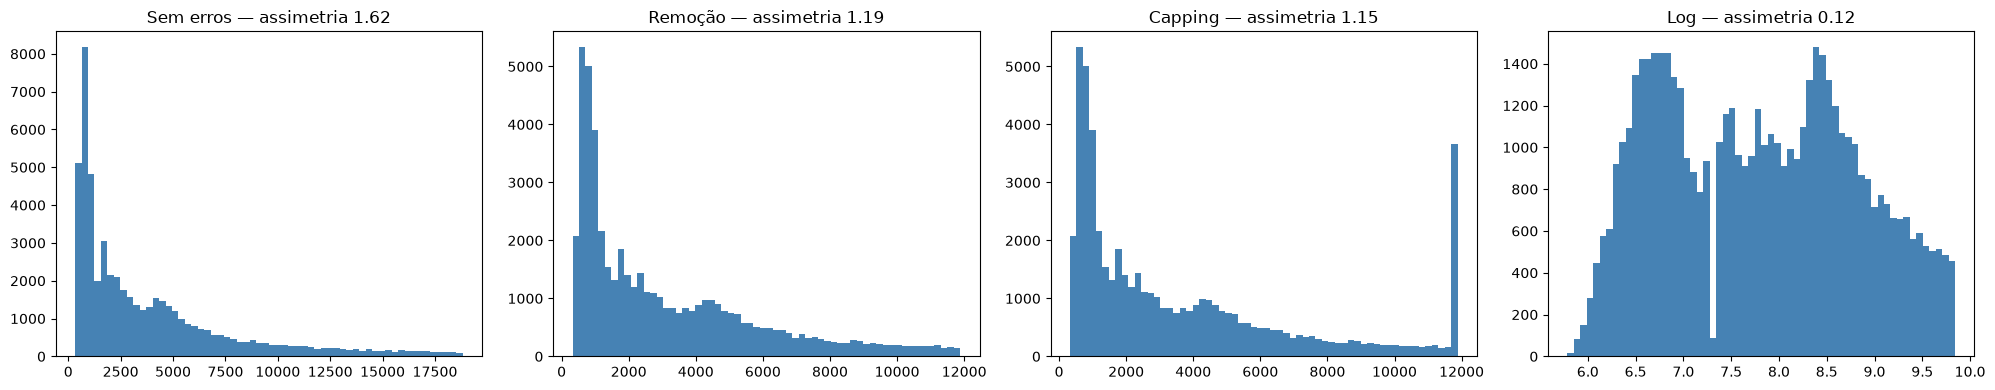

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (nome, serie) in zip(axes, [('Sem erros', base['price']), ('Remoção', df_remocao['price']),
                                     ('Capping', df_capping['price']), ('Log', df_log['price'])]):
    ax.hist(serie, bins=60, color='steelblue')
    ax.set_title(f'{nome} — assimetria {serie.skew():.2f}')
plt.tight_layout()
plt.show()

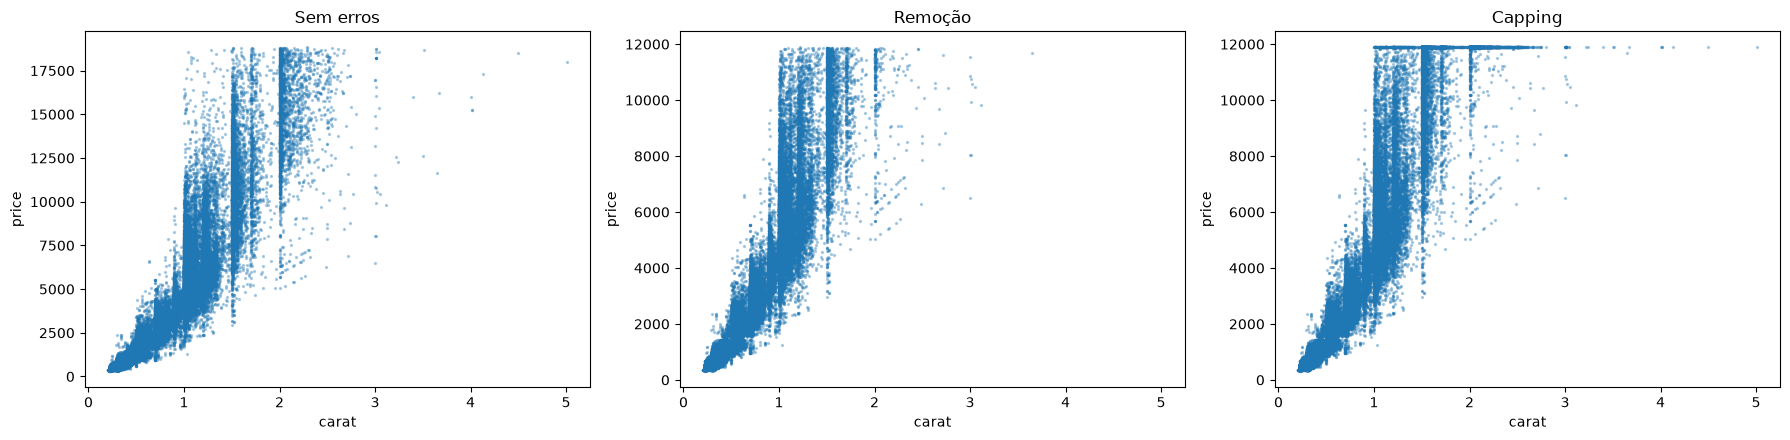

Maior diamante que sobrou na remoção: 3.65 quilates
Diamantes com preço "achatado" no capping: 3530


In [18]:
# o que a remoção e o capping fazem com a relação carat x price
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharex=True)
axes[0].scatter(base['carat'], base['price'], s=2, alpha=0.3); axes[0].set_title('Sem erros')
axes[1].scatter(df_remocao['carat'], df_remocao['price'], s=2, alpha=0.3); axes[1].set_title('Remoção')
axes[2].scatter(df_capping['carat'], df_capping['price'], s=2, alpha=0.3); axes[2].set_title('Capping')
for ax in axes:
    ax.set_xlabel('carat'); ax.set_ylabel('price')
plt.tight_layout()
plt.show()
print('Maior diamante que sobrou na remoção:', df_remocao['carat'].max(), 'quilates')
print('Diamantes com preço "achatado" no capping:', (base['price'] > sup_p).sum())

**O que cada estratégia fez:**

- **Remoção:** a base perdeu ~3.500 diamantes (6,6%), todos os mais caros. A média caiu de ~$3.930 para ~$3.160 e o desvio caiu bastante. O gráfico de dispersão mostra o problema: a relação peso x preço fica "cortada" no topo, e o maior diamante que sobrou tem 3,65 quilates (os de 4 e 5 quilates sumiram todos). Qualquer conclusão sobre diamantes caros fica impossível.
- **Capping:** mantém todas as linhas, mas cria uma "parede" artificial em ~$11.900. No histograma aparece um pico no último bin, (são 3.530 diamantes com o preço "achatado"), e no gráfico de dispersão quase todos os diamantes acima de 2 quilates passam a ter o **mesmo preço**, o que é falso. Um modelo treinado assim aprenderia que um diamante de 4 quilates custa o mesmo que um de 2.
- **Log:** não remove nem altera a ordem de ninguém. A assimetria cai de 1,6 para ~0,1 e a distribuição fica bem mais "comportada" (mas aparecem dois picos, provavelmente porque existem dois "grupos" de diamantes, pequenos e médios). E dá para voltar para dólares com `exp()` sem perder nada.

Para esse dataset, minha escolha seria: **remover só os erros de registro + usar log no preço** se for para modelagem. Remoção e capping escondem justamente os diamantes mais valiosos.

## Respostas às perguntas de reflexão

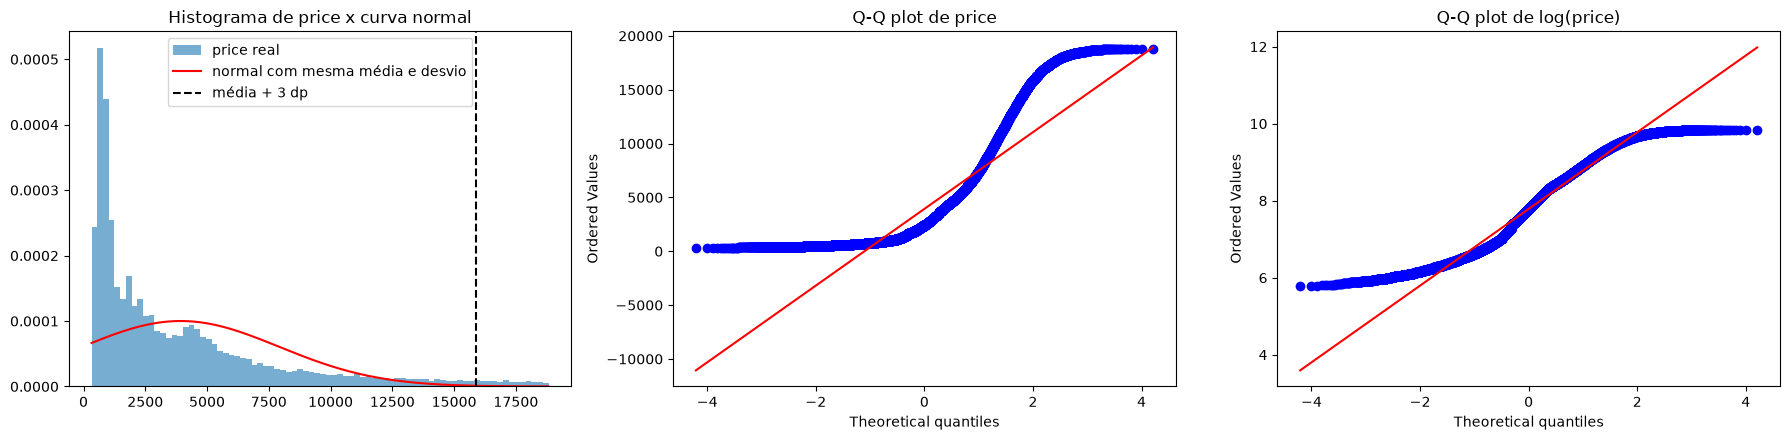

A normal com essa média e desvio colocaria 16.2% dos diamantes com preço NEGATIVO.


In [19]:
# apoio para a pergunta 1: price é normal?
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
preco = base['price']
axes[0].hist(preco, bins=80, density=True, alpha=0.6, label='price real')
xs = np.linspace(preco.min(), preco.max(), 300)
axes[0].plot(xs, stats.norm.pdf(xs, preco.mean(), preco.std()), 'r', label='normal com mesma média e desvio')
axes[0].axvline(preco.mean() + 3 * preco.std(), color='k', linestyle='--', label='média + 3 dp')
axes[0].set_title('Histograma de price x curva normal')
axes[0].legend()

stats.probplot(preco, dist='norm', plot=axes[1])
axes[1].set_title('Q-Q plot de price')

stats.probplot(np.log(preco), dist='norm', plot=axes[2])
axes[2].set_title('Q-Q plot de log(price)')
plt.tight_layout()
plt.show()

print(f'A normal com essa média e desvio colocaria {stats.norm.cdf(0, preco.mean(), preco.std()):.1%} dos diamantes com preço NEGATIVO.')

**1. O Z-score parte de uma suposição sobre a forma da distribuição. Qual? Essa suposição vale para `price`?**

O Z-score assume que os dados seguem uma distribuição **normal** (simétrica, em formato de sino). É por isso que o corte em |z| > 3 faz sentido: numa normal, só ~0,3% dos valores ficam além de 3 desvios. Para `price` isso **não vale**: o histograma mostra uma distribuição muito assimétrica, com um monte de diamantes baratos e uma cauda longa para a direita. A curva normal desenhada por cima não tem nada a ver com os dados, e com essa média e desvio ela colocaria uns 16% dos diamantes com preço negativo, o que é absurdo. No Q-Q plot, se fosse normal os pontos ficariam em cima da reta vermelha, mas eles fazem uma curva bem acentuada. Depois do log fica bem mais perto da reta. Na prática, o Z-score em `price` não "enxerga" o lado esquerdo (nunca marca diamante barato como outlier) e o limite do lado direito é influenciado pelos próprios valores extremos.

**2. Um diamante de mais de 4 quilates é um outlier a ser removido ou um diamante raro? Como o objetivo da análise muda essa resposta?**

Pelos dados, é um **diamante raro**, não um erro. São 5 pedras com dimensões coerentes com o peso e preços coerentes com o peso e a qualidade. Se ele deve ou não ficar depende do objetivo:
- Se eu estou fazendo um modelo para precificar os diamantes que uma joalheria comum vende (a grande maioria abaixo de 2 quilates), esses 5 podem atrapalhar o ajuste e quase nunca vão aparecer na prática. Removê-los (e deixar documentado que o modelo só vale até X quilates) é razoável.
- Se o objetivo é entender o mercado de pedras grandes, avaliar o estoque de alto valor ou detectar oportunidades, esses diamantes são **exatamente** o que interessa. Removê-los seria jogar fora a parte mais valiosa da análise.
- Com só 5 exemplos, também não dá para tirar muita conclusão estatística sobre essa faixa, e isso é uma informação importante por si só.

**3. Dê um exemplo de situação em que remover outliers esconderia exatamente aquilo que o negócio quer descobrir.**

**Detecção de fraude** é o exemplo mais clássico: uma compra de R$ 15 mil num cartão que normalmente gasta R$ 200 por mês é um outlier, e é justamente ela que o banco quer encontrar. Se eu "limpar" os outliers antes, o modelo de fraude nunca vê uma fraude. Outros exemplos que pensei: em monitoramento de máquinas, um pico de temperatura é o sinal de que algo vai quebrar; em vendas, os poucos clientes que compram muito (os "baleias") podem ser responsáveis por boa parte do faturamento; e aqui nos diamantes, se a pergunta for "quais pedras mais pesam no valor do estoque?", a resposta está justamente nas que o IQR manda tirar.